# 8. Model Training and Development

Having completed the preprocessing stage, we can now move on to the actual model development.

The goal is to train and compare different regression algorithms in order to determine how well they can predict appliance energy consumption 10 minutes into the future.

We will begin with a set of baseline models, using their default configurations to establish an initial point of comparison. From there, we will explore the impact of the engineered features on model performance and proceed with hyperparameter tuning to see whether further improvements can be achieved.

### 8.1 Loading and Preparing the Data

In [1]:
import pandas as pd
import sys

sys.path.append('../src')
from preprocessing import prepare_dataset

df = pd.read_csv('../data/raw/energydata_complete.csv')

X_original, y_original = prepare_dataset(df, engineer_features=False)

X_engineered, y_engineered = prepare_dataset(df, engineer_features=True)

print("Original features:", X_original.shape)
print("Engineered features:", X_engineered.shape)

Original features: (19590, 26)
Engineered features: (19590, 35)


In [2]:
from sklearn.model_selection import train_test_split

def split_dataset(X, y):
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y,
        test_size=0.30,
        shuffle=False
    )

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp,
        test_size=0.50,
        shuffle=False
    )

    return X_train, X_val, X_test, y_train, y_val, y_test

In [3]:
original_split = split_dataset(X_original, y_original)

engineered_split = split_dataset(X_engineered, y_engineered)

(
    X_train_original, X_val_original, X_test_original,
    y_train_original, y_val_original, y_test_original
) = original_split

(
    X_train_engineered, X_val_engineered, X_test_engineered,
    y_train_engineered, y_val_engineered, y_test_engineered
) = engineered_split

In [4]:
import numpy as np

y_train_original_log = np.log1p(y_train_original)
y_val_original_log = np.log1p(y_val_original)
y_test_original_log = np.log1p(y_test_original)

y_train_engineered_log = np.log1p(y_train_engineered)
y_val_engineered_log = np.log1p(y_val_engineered)
y_test_engineered_log = np.log1p(y_test_engineered)

In [5]:
split_comparison = pd.DataFrame({
    'Dataset': ['Original', 'Engineered'],
    'Features': [
        X_train_original.shape[1],
        X_train_engineered.shape[1]
    ],
    'Training observations': [
        len(X_train_original),
        len(X_train_engineered)
    ],
    'Validation observations': [
        len(X_val_original),
        len(X_val_engineered)
    ],
    'Test observations': [
        len(X_test_original),
        len(X_test_engineered)
    ],
    'Total observations': [
        len(X_train_original) + len(X_val_original) + len(X_test_original),
        len(X_train_engineered) + len(X_val_engineered) + len(X_test_engineered)
    ]
})

display(split_comparison)

,Dataset,Features,Training observations,Validation observations,Test observations,Total observations
0,Original,26,13713,2938,2939,19590
1,Engineered,35,13713,2938,2939,19590


### 8.3 Baseline Models

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [7]:
models = {
    'Linear Regression': Pipeline([
        ('model', LinearRegression())
    ]),

    'SVR': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVR())
    ]),

    'Random Forest': Pipeline([
        ('model', RandomForestRegressor(random_state=42))
    ]),

    'MLP Regressor': Pipeline([
        ('scaler', StandardScaler()),
        ('model', MLPRegressor(random_state=42, max_iter=1500, early_stopping=False))
    ])
}

for name, model in models.items():
    print(name, ":", model)

Linear Regression : Pipeline(steps=[('model', LinearRegression())])
SVR : Pipeline(steps=[('scaler', StandardScaler()), ('model', SVR())])
Random Forest : Pipeline(steps=[('model', RandomForestRegressor(random_state=42))])
MLP Regressor : Pipeline(steps=[('scaler', StandardScaler()),
                ('model', MLPRegressor(max_iter=1500, random_state=42))])


In [8]:
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone

def evaluate_models(models, X_train, y_train, X_val, y_val):

    results = []

    for name, model in models.items():

        estimator = clone(model)
        estimator.fit(X_train, y_train)

        y_pred_log = estimator.predict(X_val)
        y_pred = np.expm1(y_pred_log)

        results.append({
            'Model': name,
            'MAE': mean_absolute_error(y_val, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_val, y_pred)),
            'R2': r2_score(y_val, y_pred)
        })

    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(by='RMSE').reset_index(drop=True)

    return results_df


In [9]:

original_results = evaluate_models(
    models,
    X_train_original, y_train_original_log,
    X_val_original, y_val_original
)

engineered_results = evaluate_models(
    models,
    X_train_engineered, y_train_engineered_log,
    X_val_engineered, y_val_engineered
)

original_results['Dataset'] = 'Original'
engineered_results['Dataset'] = 'Engineered'

comparison_results = pd.concat(
    [original_results, engineered_results],
    ignore_index=True
)

comparison_results = comparison_results[
    ['Model', 'Dataset', 'MAE', 'RMSE', 'R2']
].sort_values(
    by=['Model', 'Dataset']
).reset_index(drop=True)


,Model,Dataset,MAE,RMSE,R2
0,Linear Regression,Engineered,28.973061,74.692114,0.314399
1,Linear Regression,Original,31.955748,89.350935,0.018884
2,MLP Regressor,Engineered,35.127937,75.377028,0.301768
3,MLP Regressor,Original,36.702838,74.881373,0.310920
4,Random Forest,Engineered,29.932896,63.295061,0.507664
5,Random Forest,Original,33.168974,69.255412,0.410574
6,SVR,Engineered,25.573602,64.194171,0.493577
7,SVR,Original,26.839258,65.479066,0.473102


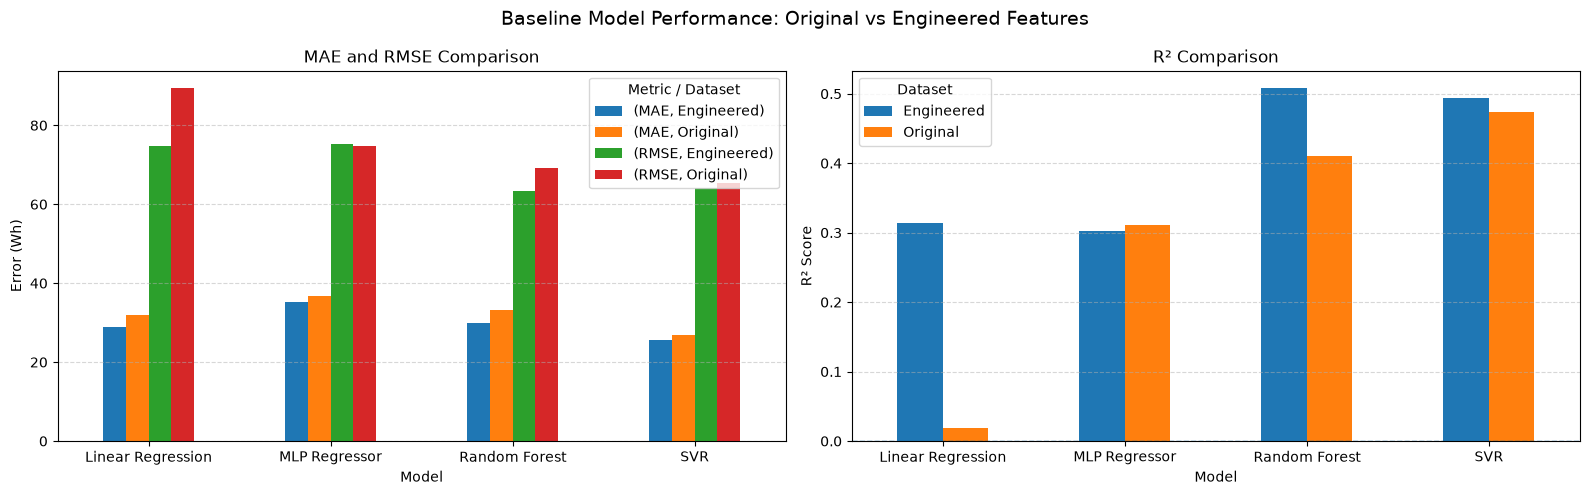

In [10]:

import matplotlib.pyplot as plt

display(comparison_results)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

error_comparison = comparison_results.pivot(
    index='Model',
    columns='Dataset',
    values=['MAE', 'RMSE']
)

error_comparison.plot(
    kind='bar',
    ax=axes[0],
    rot=0
)

axes[0].set_title('MAE and RMSE Comparison')
axes[0].set_ylabel('Error (Wh)')
axes[0].set_xlabel('Model')
axes[0].legend(title='Metric / Dataset')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

r2_comparison = comparison_results.pivot(
    index='Model',
    columns='Dataset',
    values='R2'
)

r2_comparison.plot(
    kind='bar',
    ax=axes[1],
    rot=0
)

axes[1].set_title('R² Comparison')
axes[1].set_ylabel('R² Score')
axes[1].set_xlabel('Model')
axes[1].axhline(y=0, linestyle='--', linewidth=1)
axes[1].legend(title='Dataset')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

fig.suptitle(
    'Baseline Model Performance: Original vs Engineered Features',
    fontsize=14
)

plt.tight_layout()
plt.show()


#### Naive Baseline

In [11]:
y_pred_naive = X_val_engineered['Appliances']

persistence_val = pd.DataFrame([{
    'Model': 'Persistence (naive)',
    'MAE': mean_absolute_error(y_val_engineered, y_pred_naive),
    'RMSE': np.sqrt(mean_squared_error(y_val_engineered, y_pred_naive)),
    'R2': r2_score(y_val_engineered, y_pred_naive)
}])

display(persistence_val)

,Model,MAE,RMSE,R2
0,Persistence (naive),25.786249,65.513108,0.472554


### 8.4 Hyperparameter Tuning

In [12]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

tscv = TimeSeriesSplit(n_splits=5)

#### 8.4.2 Support Vector Regression (SVR)

#### Baseline Cross-Validation

In [13]:
svr_cv_original = cross_val_score(
    models['SVR'],
    X_train_original,
    y_train_original_log,
    cv=tscv,
    scoring='neg_root_mean_squared_error'
)

svr_cv_engineered = cross_val_score(
    models['SVR'],
    X_train_engineered,
    y_train_engineered_log,
    cv=tscv,
    scoring='neg_root_mean_squared_error'
)

svr_cv_original = -svr_cv_original
svr_cv_engineered = -svr_cv_engineered

print("SVR - Original Features")
print("Fold RMSE:", svr_cv_original)
print("Mean RMSE:", svr_cv_original.mean())
print("Standard Deviation:", svr_cv_original.std())

print("\nSVR - Engineered Features")
print("Fold RMSE:", svr_cv_engineered)
print("Mean RMSE:", svr_cv_engineered.mean())
print("Standard Deviation:", svr_cv_engineered.std())


SVR - Original Features
Fold RMSE: [0.49259024 0.51822762 0.47166816 0.41117882 0.42971209]
Mean RMSE: 0.4646753859396953
Standard Deviation: 0.039446913336230446

SVR - Engineered Features
Fold RMSE: [0.46562056 0.49314151 0.46126434 0.38774223 0.38633176]
Mean RMSE: 0.4388200793809422
Standard Deviation: 0.043673330867769186


#### Hyperparameter Tuning

In [14]:
svr_param_grid = {
    'model__C': [1, 10],
    'model__epsilon': [0.1, 1],
    'model__gamma': ['scale', 'auto']
}

In [15]:
from sklearn.model_selection import GridSearchCV

svr_grid_original = GridSearchCV(
    estimator=models['SVR'],
    param_grid=svr_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    refit=True,
    n_jobs=4,
    verbose=1
)

svr_grid_engineered = GridSearchCV(
    estimator=models['SVR'],
    param_grid=svr_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    refit=True,
    n_jobs = 4,
    verbose=1
)

svr_grid_original.fit(X_train_original, y_train_original_log)

svr_grid_engineered.fit(X_train_engineered, y_train_engineered_log)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Fitting 5 folds for each of 8 candidates, totalling 40 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...del', SVR())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [1, 10], 'model__epsilon': [0.1, 1], 'model__gamma': ['scale', 'auto']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx

#### Inspecting Results

In [16]:
print("SVR - Original Features")
print("Best Parameters:", svr_grid_original.best_params_)
print("Best CV RMSE:", -svr_grid_original.best_score_)

print("\nSVR - Engineered Features")
print("Best Parameters:", svr_grid_engineered.best_params_)
print("Best CV RMSE:", -svr_grid_engineered.best_score_)

SVR - Original Features
Best Parameters: {'model__C': 1, 'model__epsilon': 0.1, 'model__gamma': 'scale'}
Best CV RMSE: 0.4646753859396953

SVR - Engineered Features
Best Parameters: {'model__C': 1, 'model__epsilon': 0.1, 'model__gamma': 'scale'}
Best CV RMSE: 0.4388200793809422


#### Validation Performance

After identifying the best hyperparameter configurations, we will evaluate the resulting models on their respective validation datasets.

This allows us to assess whether the improvements observed during cross-validation also translate to unseen observations. We will use MAE, RMSE and R² to compare the tuned models against their baseline counterparts.

In [17]:
svr_pred_original = np.expm1(svr_grid_original.best_estimator_.predict(
    X_val_original
))

svr_pred_engineered = np.expm1(svr_grid_engineered.best_estimator_.predict(
    X_val_engineered
))

svr_tuned_results = pd.DataFrame([
    {
        'Model': 'SVR',
        'Dataset': 'Original',
        'MAE': mean_absolute_error(y_val_original, svr_pred_original),
        'RMSE': np.sqrt(mean_squared_error(y_val_original, svr_pred_original)),
        'R2': r2_score(y_val_original, svr_pred_original)
    },
    {
        'Model': 'SVR',
        'Dataset': 'Engineered',
        'MAE': mean_absolute_error(y_val_engineered, svr_pred_engineered),
        'RMSE': np.sqrt(mean_squared_error(y_val_engineered, svr_pred_engineered)),
        'R2': r2_score(y_val_engineered, svr_pred_engineered)
    }
])

display(svr_tuned_results)

,Model,Dataset,MAE,RMSE,R2
0,SVR,Original,26.839258,65.479066,0.473102
1,SVR,Engineered,25.573602,64.194171,0.493577


### 8.4.3 Random Forest Regressor

#### Baseline Cross-Validation

In [18]:
rf_cv_original = cross_val_score(
    models['Random Forest'],
    X_train_original,
    y_train_original_log,
    cv=tscv,
    scoring='neg_root_mean_squared_error'
)

rf_cv_engineered = cross_val_score(
    models['Random Forest'],
    X_train_engineered,
    y_train_engineered_log,
    cv=tscv,
    scoring='neg_root_mean_squared_error'
)

rf_cv_original = -rf_cv_original
rf_cv_engineered = -rf_cv_engineered

print("Random Forest - Original Features")
print("Fold RMSE:", rf_cv_original)
print("Mean RMSE:", rf_cv_original.mean())
print("Standard Deviation:", rf_cv_original.std())

print("\nRandom Forest - Engineered Features")
print("Fold RMSE:", rf_cv_engineered)
print("Mean RMSE:", rf_cv_engineered.mean())
print("Standard Deviation:", rf_cv_engineered.std())


Random Forest - Original Features
Fold RMSE: [0.47263495 0.45007664 0.42192418 0.40194704 0.42597226]
Mean RMSE: 0.43451101579611395
Standard Deviation: 0.02444370754103423

Random Forest - Engineered Features
Fold RMSE: [0.4321236  0.42000357 0.38524851 0.35607889 0.38923373]
Mean RMSE: 0.39653766028241727
Standard Deviation: 0.02696186911821147


#### Hyperparameter Tuning

In [19]:

rf_param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 20],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2]
}


In [20]:

rf_grid_original = GridSearchCV(
    estimator=models['Random Forest'],
    param_grid=rf_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    refit=True,
    n_jobs=4,
    verbose=1
)
rf_grid_engineered = GridSearchCV(
    estimator=models['Random Forest'],
    param_grid=rf_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    refit=True,
    n_jobs=4,
    verbose=1
)

rf_grid_original.fit(X_train_original, y_train_original_log)

rf_grid_engineered.fit(X_train_engineered, y_train_engineered_log)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 20], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know

#### Inspecting Results

In [21]:

print("Random Forest - Original Features")
print("Best Parameters:", rf_grid_original.best_params_)
print("Best CV RMSE:", -rf_grid_original.best_score_)

print("\nRandom Forest - Engineered Features")
print("Best Parameters:", rf_grid_engineered.best_params_)
print("Best CV RMSE:", -rf_grid_engineered.best_score_)

Random Forest - Original Features
Best Parameters: {'model__max_depth': 20, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best CV RMSE: 0.40078992671205793

Random Forest - Engineered Features
Best Parameters: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Best CV RMSE: 0.37225119923274314


#### Validation Performance

In [22]:
rf_pred_original = np.expm1(rf_grid_original.best_estimator_.predict(
    X_val_original
))

rf_pred_engineered = np.expm1(rf_grid_engineered.best_estimator_.predict(
    X_val_engineered
))

rf_tuned_results = pd.DataFrame([
    {
        'Model': 'Random Forest',
        'Dataset': 'Original',
        'MAE': mean_absolute_error(y_val_original, rf_pred_original),
        'RMSE': np.sqrt(mean_squared_error(y_val_original, rf_pred_original)),
        'R2': r2_score(y_val_original, rf_pred_original)
    },
    {
        'Model': 'Random Forest',
        'Dataset': 'Engineered',
        'MAE': mean_absolute_error(y_val_engineered, rf_pred_engineered),
        'RMSE': np.sqrt(mean_squared_error(y_val_engineered, rf_pred_engineered)),
        'R2': r2_score(y_val_engineered, rf_pred_engineered)
    }
])

display(rf_tuned_results)


,Model,Dataset,MAE,RMSE,R2
0,Random Forest,Original,29.211898,63.610267,0.502748
1,Random Forest,Engineered,26.622946,59.558748,0.564074


### 8.4.4 Multi-Layer Perceptron Regressor (MLPRegressor)

#### Baseline Cross-Validation

In [23]:
mlp_cv_original = cross_val_score(
    models['MLP Regressor'],
    X_train_original,
    y_train_original_log,
    cv=tscv,
    n_jobs=4,
    scoring='neg_root_mean_squared_error'
)

mlp_cv_engineered = cross_val_score(
    models['MLP Regressor'],
    X_train_engineered,
    y_train_engineered_log,
    cv=tscv,
    n_jobs=4,
    scoring='neg_root_mean_squared_error'
)

mlp_cv_original = -mlp_cv_original
mlp_cv_engineered = -mlp_cv_engineered

print("MLP Regressor - Original Features")
print("Fold RMSE:", mlp_cv_original)
print("Mean RMSE:", mlp_cv_original.mean())
print("Standard Deviation:", mlp_cv_original.std())

print("\nMLP Regressor - Engineered Features")
print("Fold RMSE:", mlp_cv_engineered)
print("Mean RMSE:", mlp_cv_engineered.mean())
print("Standard Deviation:", mlp_cv_engineered.std())


MLP Regressor - Original Features
Fold RMSE: [2.09690897 0.72477296 0.74259069 0.45464542 0.46223796]
Mean RMSE: 0.8962312001742949
Standard Deviation: 0.6128586414504889

MLP Regressor - Engineered Features
Fold RMSE: [1.66015703 0.89203623 0.78594714 0.53425822 0.50964887]
Mean RMSE: 0.8764094987344553
Standard Deviation: 0.41815515734339803


#### Hyperparameter Tuning

In [24]:

mlp_param_grid = {
    'model__hidden_layer_sizes': [(50,), (100,)],
    'model__activation': ['relu', 'tanh'],
    'model__alpha': [0.0001, 0.001],
    'model__learning_rate_init': [0.001, 0.01]
}

In [25]:
mlp_grid_original = GridSearchCV(
    estimator=models['MLP Regressor'],
    param_grid=mlp_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    refit=True,
    n_jobs=6,
    verbose=1
)

mlp_grid_engineered = GridSearchCV(
    estimator=models['MLP Regressor'],
    param_grid=mlp_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    refit=True,
    n_jobs=6,
    verbose=1
)


mlp_grid_original.fit(X_train_original, y_train_original_log)

mlp_grid_engineered.fit(X_train_engineered, y_train_engineered_log)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__activation': ['relu', 'tanh'], 'model__alpha': [0.0001, 0.001], 'model__hidden_layer_sizes': [(50,), (100,)], 'model__learning_rate_init': [0.001, 0.01]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",6
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``sco

#### Inspecting Results

In [26]:
print("MLP Regressor - Original Features")
print("Best Parameters:", mlp_grid_original.best_params_)
print("Best CV RMSE:", -mlp_grid_original.best_score_)

print("\nMLP Regressor - Engineered Features")
print("Best Parameters:", mlp_grid_engineered.best_params_)
print("Best CV RMSE:", -mlp_grid_engineered.best_score_)

MLP Regressor - Original Features
Best Parameters: {'model__activation': 'tanh', 'model__alpha': 0.001, 'model__hidden_layer_sizes': (50,), 'model__learning_rate_init': 0.001}
Best CV RMSE: 0.5452616777234769

MLP Regressor - Engineered Features
Best Parameters: {'model__activation': 'tanh', 'model__alpha': 0.001, 'model__hidden_layer_sizes': (50,), 'model__learning_rate_init': 0.001}
Best CV RMSE: 0.7556035947791154


#### Validation Performance

After identifying the best hyperparameter configurations, we will evaluate the resulting models on their respective validation datasets.

In [27]:
mlp_pred_original = np.expm1(mlp_grid_original.best_estimator_.predict(
    X_val_original
))

mlp_pred_engineered = np.expm1(mlp_grid_engineered.best_estimator_.predict(
    X_val_engineered
))

mlp_tuned_results = pd.DataFrame([
    {
        'Model': 'MLP Regressor',
        'Dataset': 'Original',
        'MAE': mean_absolute_error(y_val_original, mlp_pred_original),
        'RMSE': np.sqrt(mean_squared_error(y_val_original, mlp_pred_original)),
        'R2': r2_score(y_val_original, mlp_pred_original)
    },
    {
        'Model': 'MLP Regressor',
        'Dataset': 'Engineered',
        'MAE': mean_absolute_error(y_val_engineered, mlp_pred_engineered),
        'RMSE': np.sqrt(mean_squared_error(y_val_engineered, mlp_pred_engineered)),
        'R2': r2_score(y_val_engineered, mlp_pred_engineered)
    }
])

display(mlp_tuned_results)


,Model,Dataset,MAE,RMSE,R2
0,MLP Regressor,Original,28.854819,65.407690,0.474250
1,MLP Regressor,Engineered,27.949100,63.189558,0.509304


### 8.5 Comparison of Tuned Models

In [28]:
linear_results = comparison_results[
    comparison_results['Model'] == 'Linear Regression'
]

final_comparison = pd.concat(
    [
        linear_results,
        svr_tuned_results,
        rf_tuned_results,
        mlp_tuned_results
    ],
    ignore_index=True
)

final_comparison = final_comparison.sort_values(
    by=['Dataset', 'RMSE']
).reset_index(drop=True)

display(final_comparison)

,Model,Dataset,MAE,RMSE,R2
0,Random Forest,Engineered,26.622946,59.558748,0.564074
1,MLP Regressor,Engineered,27.949100,63.189558,0.509304
2,SVR,Engineered,25.573602,64.194171,0.493577
3,Linear Regression,Engineered,28.973061,74.692114,0.314399
4,Random Forest,Original,29.211898,63.610267,0.502748
5,MLP Regressor,Original,28.854819,65.407690,0.474250
6,SVR,Original,26.839258,65.479066,0.473102
7,Linear Regression,Original,31.955748,89.350935,0.018884


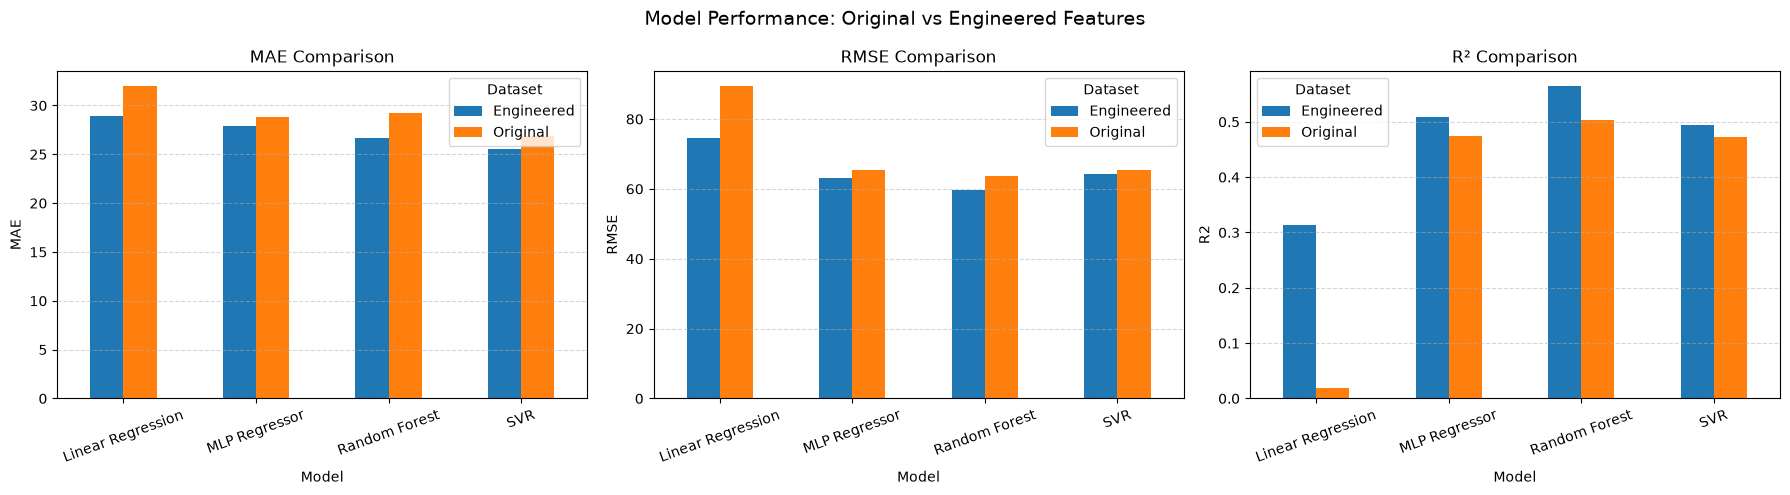

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = ['MAE', 'RMSE', 'R2']
titles = ['MAE Comparison', 'RMSE Comparison', 'R² Comparison']

for ax, metric, title in zip(axes, metrics, titles):

    pivot = final_comparison.pivot(
        index='Model',
        columns='Dataset',
        values=metric
    )

    pivot.plot(kind='bar', ax=ax, rot=20)

    ax.set_title(title)
    ax.set_xlabel('Model')
    ax.set_ylabel(metric)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle(
    'Model Performance: Original vs Engineered Features',
    fontsize=14
)

plt.tight_layout()
plt.show()

### 8.6 Final Model Selection

Based on the validation results, we selected `Random Forest Regressor` trained on the engineered dataset as our final model candidate.

# 9. Final Model Evaluation

In [33]:

from sklearn.base import clone

X_train_val = pd.concat(
    [X_train_engineered, X_val_engineered]
)

y_train_val_log = pd.concat(
    [y_train_engineered_log, y_val_engineered_log]
)

final_model = clone(rf_grid_engineered.best_estimator_)

final_model.fit(X_train_val, y_train_val_log)

y_test_pred_log = final_model.predict(X_test_engineered)
y_test_pred = np.expm1(y_test_pred_log)

final_results = pd.DataFrame([{
    'Model': 'Random Forest',
    'Dataset': 'Engineered',
    'MAE': mean_absolute_error(y_test_engineered, y_test_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test_engineered, y_test_pred)),
    'R2': r2_score(y_test_engineered, y_test_pred)
}])

display(final_results)


,Model,Dataset,MAE,RMSE,R2
0,Random Forest,Engineered,31.560983,62.830196,0.523021


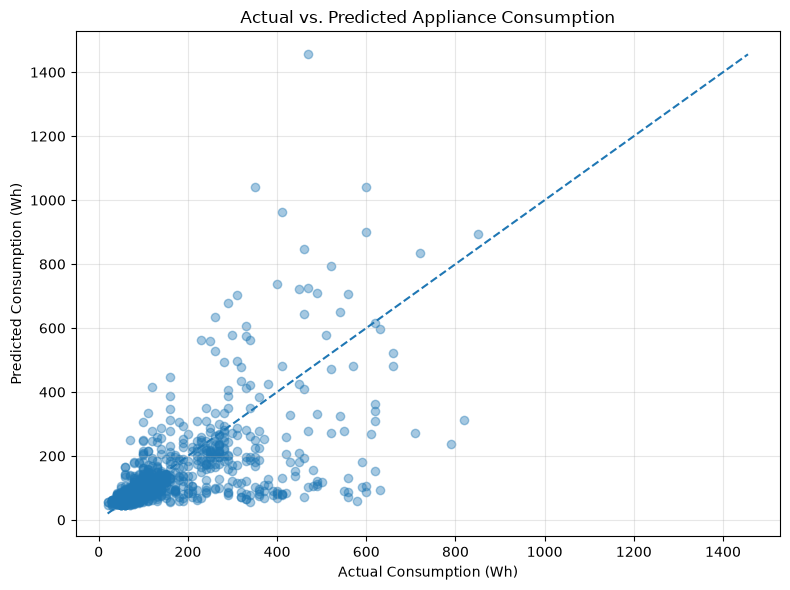

In [31]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_engineered,
    y_test_pred,
    alpha=0.4
)

min_value = min(y_test_engineered.min(), y_test_pred.min())
max_value = max(y_test_engineered.max(), y_test_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.title('Actual vs. Predicted Appliance Consumption')
plt.xlabel('Actual Consumption (Wh)')
plt.ylabel('Predicted Consumption (Wh)')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

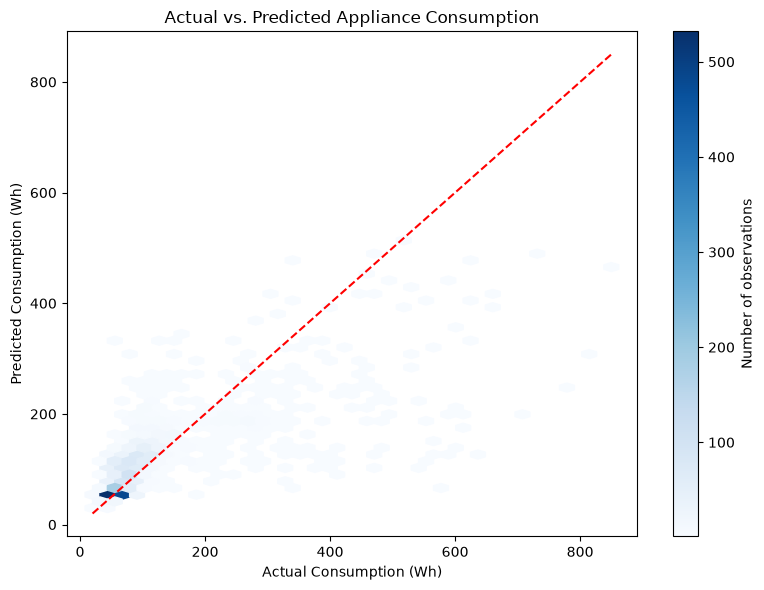

In [34]:
plt.figure(figsize=(8, 6))

plt.hexbin(
    y_test_engineered,
    y_test_pred,
    gridsize=35,
    cmap='Blues',
    mincnt=1
)

min_value = min(y_test_engineered.min(), y_test_pred.min())
max_value = max(y_test_engineered.max(), y_test_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--',
    color='red'
)

plt.colorbar(label='Number of observations')

plt.title('Actual vs. Predicted Appliance Consumption')
plt.xlabel('Actual Consumption (Wh)')
plt.ylabel('Predicted Consumption (Wh)')

plt.tight_layout()
plt.show()